In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/raw/Kerala-Rainfall-Historical.csv")

# Display basic information
print("Dataset Shape:", df.shape)
print("\nDataset Information:")
df.info()

Dataset Shape: (117, 19)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 117 entries, 0 to 116
Data columns (total 19 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   SUBDIVISION  117 non-null    str    
 1   YEAR         117 non-null    int64  
 2   JAN          117 non-null    float64
 3   FEB          117 non-null    float64
 4   MAR          117 non-null    float64
 5   APR          117 non-null    float64
 6   MAY          117 non-null    float64
 7   JUN          117 non-null    float64
 8   JUL          117 non-null    float64
 9   AUG          117 non-null    float64
 10  SEP          117 non-null    float64
 11  OCT          117 non-null    float64
 12  NOV          117 non-null    float64
 13  DEC          117 non-null    float64
 14  ANNUAL       117 non-null    float64
 15  JF           117 non-null    float64
 16  MAM          117 non-null    float64
 17  JJAS         117 non-null    float64
 18  OND          1

In [2]:
# 1. Check for duplicate records
print("Duplicate rows:", df.duplicated().sum())

# 2. Check for duplicate years
print("Duplicate years:", df["YEAR"].duplicated().sum())

# 3. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 4. Check unique subdivisions
print("\nSubdivisions:")
print(df["SUBDIVISION"].unique())

# 5. Check year range
print("\nYear Range:")
print(df["YEAR"].min(), "to", df["YEAR"].max())

# 6. Check descriptive statistics
print("\nDescriptive Statistics:")
display(df.describe().round(2))

Duplicate rows: 0
Duplicate years: 0

Missing Values:
SUBDIVISION    0
YEAR           0
JAN            0
FEB            0
MAR            0
APR            0
MAY            0
JUN            0
JUL            0
AUG            0
SEP            0
OCT            0
NOV            0
DEC            0
ANNUAL         0
JF             0
MAM            0
JJAS           0
OND            0
dtype: int64

Subdivisions:
<StringArray>
['Kerala']
Length: 1, dtype: str

Year Range:
1901 to 2017

Descriptive Statistics:


,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,JF,MAM,JJAS,OND
count,117.00,117.00,117.00,117.00,117.00,117.00,117.00,117.00,117.00,117.00,117.00,117.00,117.00,117.00,117.00,117.00,117.00,117.00
mean,1959.00,12.17,15.37,37.13,109.42,229.98,653.16,695.98,420.69,245.86,291.94,162.56,39.98,2914.25,27.54,376.52,2015.69,494.48
std,33.92,15.43,16.13,30.46,45.17,148.01,186.22,226.57,159.34,123.27,95.06,83.73,36.82,430.29,22.22,149.91,388.18,132.03
min,1901.00,0.00,0.00,0.10,13.10,53.40,196.80,167.50,178.60,41.30,68.50,31.50,0.10,1870.90,0.30,89.90,1104.30,166.60
25%,1930.00,2.40,4.70,18.10,71.50,124.50,541.70,532.00,315.30,150.10,221.60,92.90,10.20,2621.70,10.30,277.80,1749.20,406.50
50%,1959.00,6.00,8.40,28.30,108.40,190.60,625.80,687.30,385.20,223.90,282.60,153.00,31.10,2931.10,20.50,342.00,1947.50,500.80
75%,1988.00,16.90,21.40,50.10,135.10,265.40,788.50,831.60,495.00,335.60,354.10,219.10,54.10,3151.50,40.60,436.90,2231.20,584.00
max,2017.00,83.50,79.00,217.20,238.00,738.80,1098.20,1526.50,1199.20,526.70,567.90,365.60,202.30,4257.80,98.10,915.20,3451.30,823.30


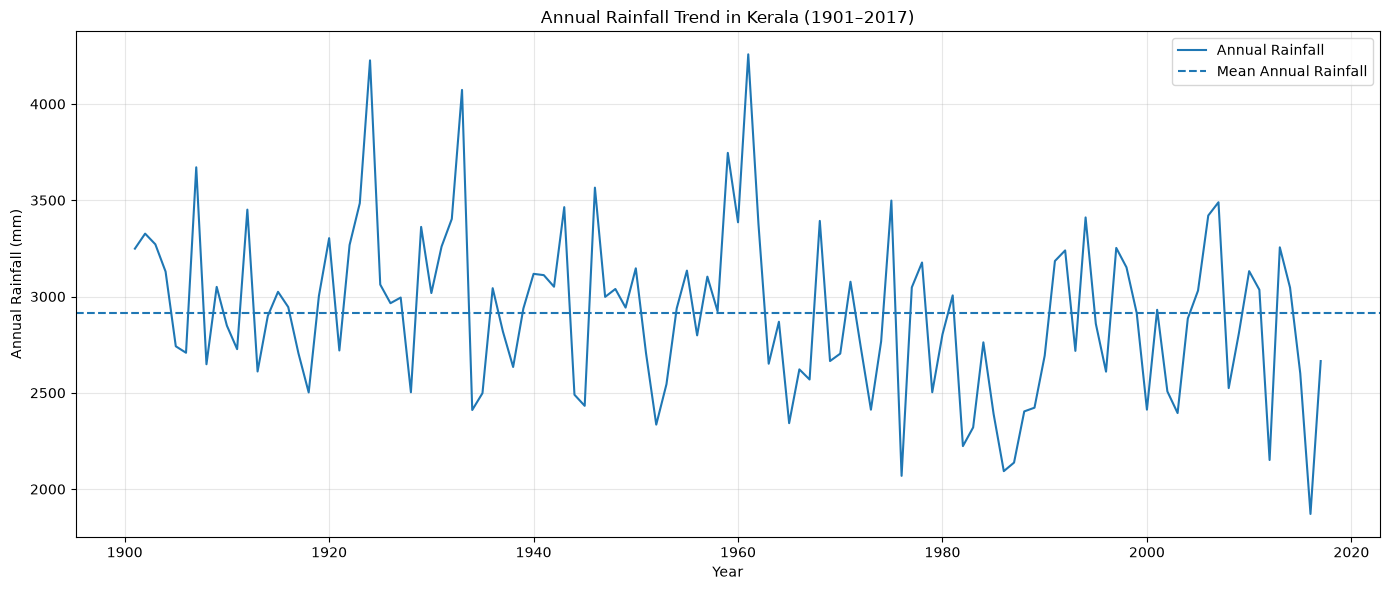

In [4]:
# Annual rainfall trend over time

plt.figure(figsize=(14, 6))

plt.plot(
    df["YEAR"],
    df["ANNUAL"],
    linewidth=1.5,
    label="Annual Rainfall"
)

plt.axhline(
    df["ANNUAL"].mean(),
    linestyle="--",
    label="Mean Annual Rainfall"
)

plt.title("Annual Rainfall Trend in Kerala (1901–2017)")
plt.xlabel("Year")
plt.ylabel("Annual Rainfall (mm)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Observation: Annual Rainfall Trend

The annual rainfall trend in Kerala from 1901 to 2017 shows considerable year-to-year variability. Several years recorded rainfall substantially above or below the historical mean of approximately 2914.25 mm.

The visualisation does not indicate an obvious consistent long-term increasing trend. Instead, rainfall appears to fluctuate considerably across the observation period.

This variability highlights the importance of investigating historical rainfall patterns when studying flood-year classification.

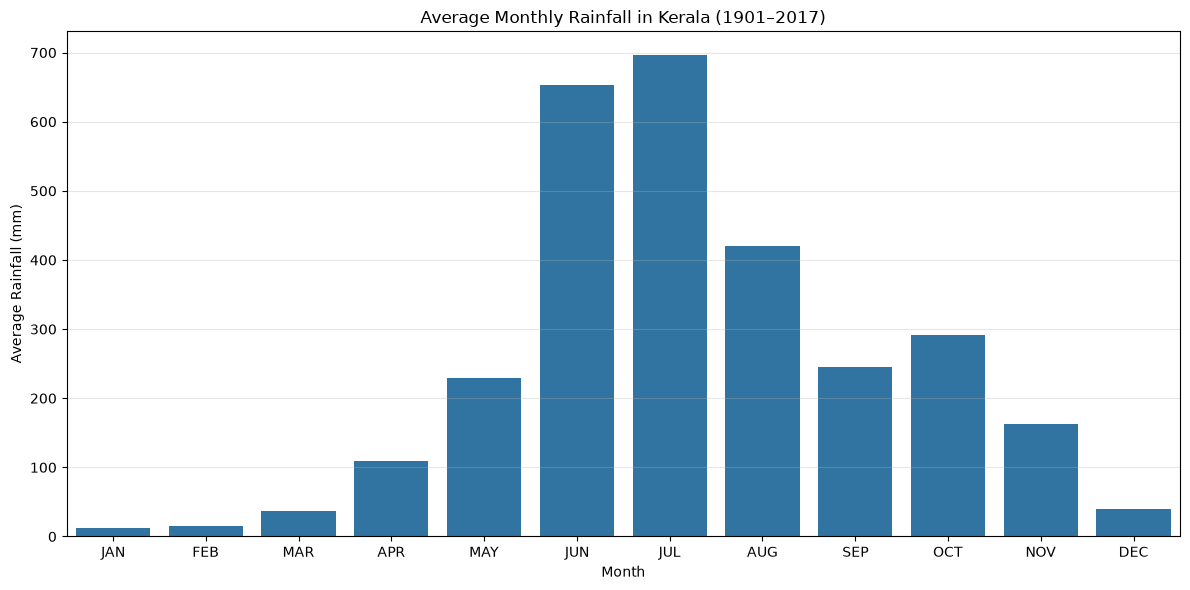

In [5]:
# Calculate average rainfall for each month

monthly_columns = [
    "JAN", "FEB", "MAR", "APR", "MAY", "JUN",
    "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"
]

monthly_avg = df[monthly_columns].mean()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=monthly_avg.index,
    y=monthly_avg.values
)

plt.title("Average Monthly Rainfall in Kerala (1901–2017)")
plt.xlabel("Month")
plt.ylabel("Average Rainfall (mm)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


#### Observation: Monthly Rainfall Distribution

The monthly rainfall distribution indicates a strong seasonal pattern in Kerala. Rainfall increases considerably from April and reaches its highest average values during June and July.

July records the highest average monthly rainfall, followed by June. Rainfall gradually decreases after July, although substantial precipitation continues during August, September and October.

The relatively low rainfall during January and February contrasts with the heavy monsoon months. This seasonal variation highlights the importance of monsoon rainfall in understanding Kerala's historical rainfall patterns.


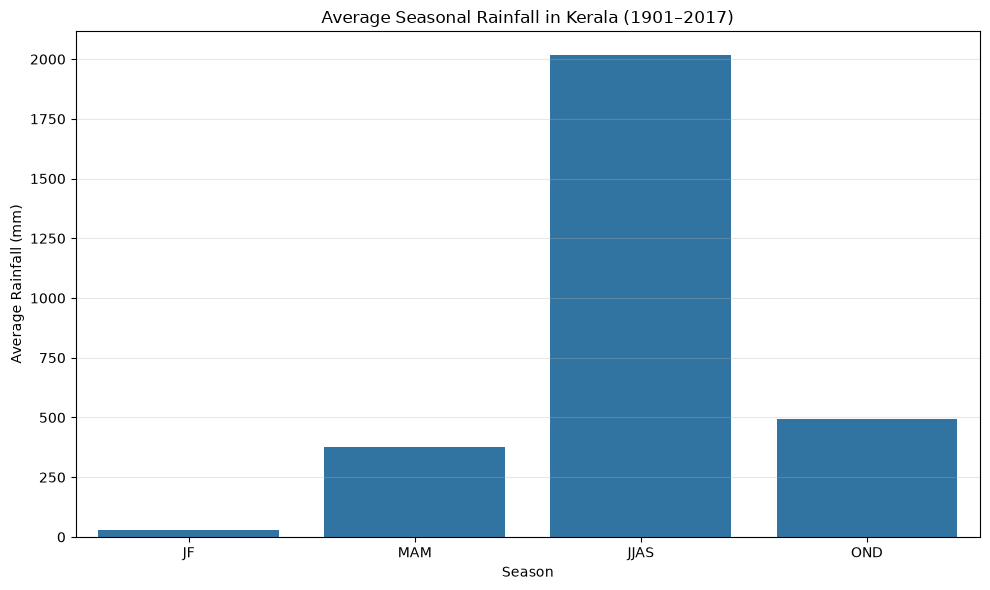

In [6]:
# Calculate average seasonal rainfall

seasonal_columns = ["JF", "MAM", "JJAS", "OND"]

seasonal_avg = df[seasonal_columns].mean()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=seasonal_avg.index,
    y=seasonal_avg.values
)

plt.title("Average Seasonal Rainfall in Kerala (1901–2017)")
plt.xlabel("Season")
plt.ylabel("Average Rainfall (mm)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#### Observation: Seasonal Rainfall Distribution

The seasonal rainfall distribution demonstrates that June–September (JJAS) is the dominant rainfall season in Kerala, with an average rainfall of approximately 2015.69 mm.

October–December (OND) contributes the second largest seasonal rainfall, followed by March–May (MAM). January–February (JF) records the lowest average rainfall.

The findings highlight the substantial contribution of the southwest monsoon to Kerala's annual rainfall and support further investigation of monsoon rainfall patterns for flood-year classification.

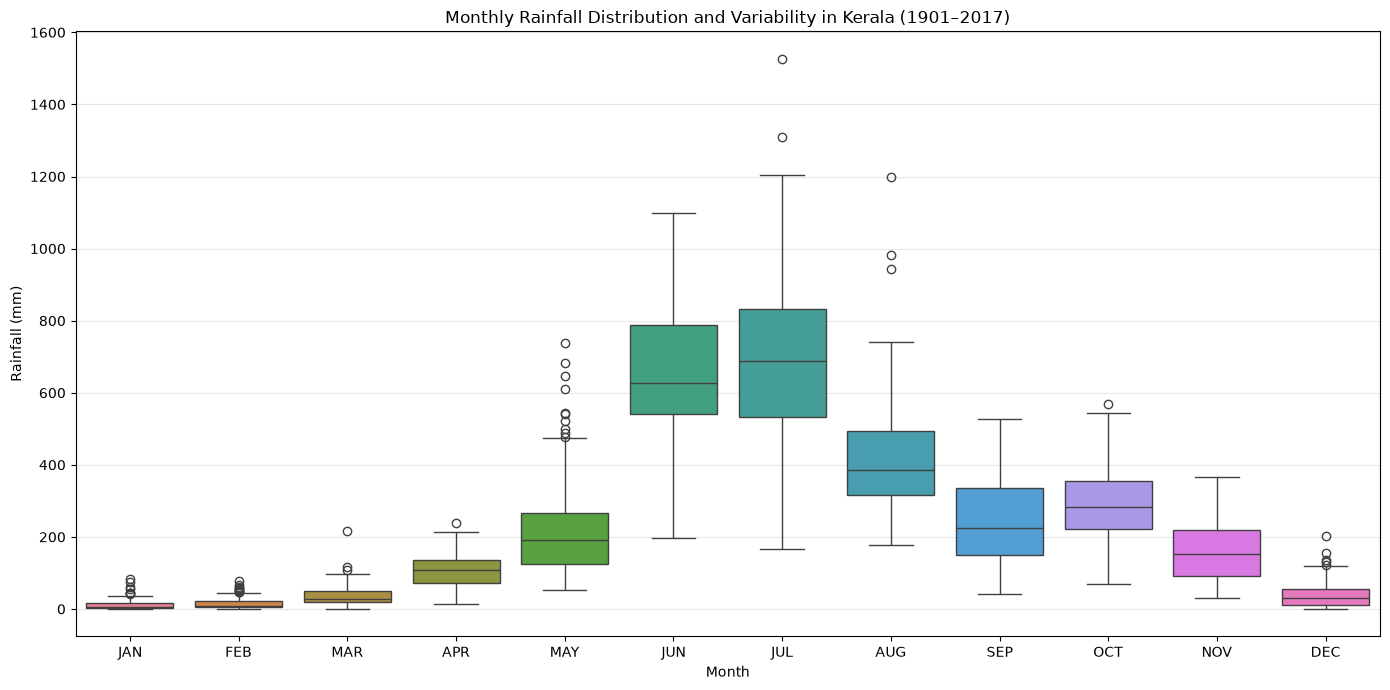

In [7]:
# Monthly rainfall variability using boxplots

plt.figure(figsize=(14, 7))

sns.boxplot(data=df[monthly_columns])

plt.title("Monthly Rainfall Distribution and Variability in Kerala (1901–2017)")
plt.xlabel("Month")
plt.ylabel("Rainfall (mm)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#### Observation: Monthly Rainfall Variability

The boxplot illustrates considerable variation in monthly rainfall across Kerala between 1901 and 2017.

June and July exhibit higher rainfall levels and wider distributions compared with most other months. Several potential outliers are also observed, particularly during May, July and August.

These extreme observations may represent unusually high rainfall events and are potentially relevant to the study of flood-year classification. Therefore, they will not be removed automatically during preprocessing.


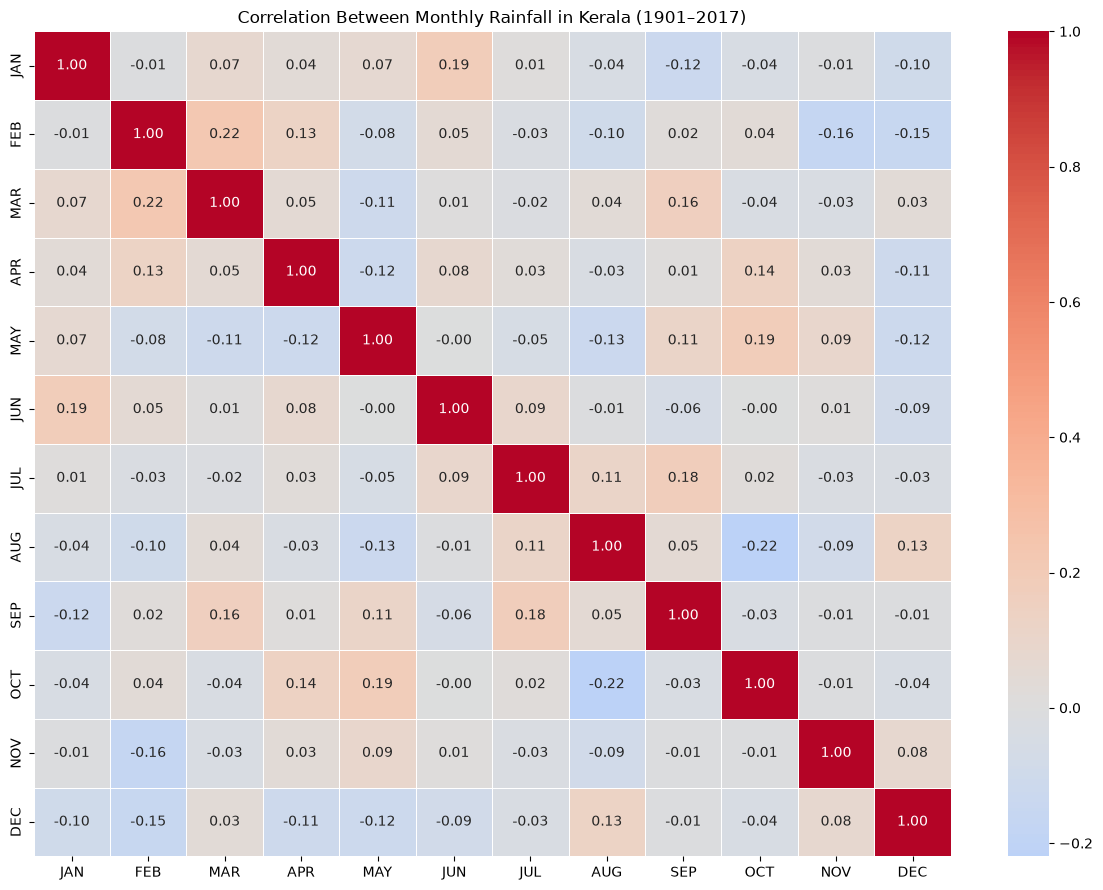

In [8]:
# Correlation between monthly rainfall variables

monthly_corr = df[monthly_columns].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    monthly_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Between Monthly Rainfall in Kerala (1901–2017)")
plt.tight_layout()
plt.show()

#### Observation: Correlation Analysis

The correlation heatmap indicates generally weak linear relationships between individual monthly rainfall variables across the observation period.

The strongest positive correlation is observed between February and March, at approximately 0.22, while the strongest negative correlation is between August and October, at approximately -0.22.

Most monthly rainfall pairs exhibit correlation values relatively close to zero. This suggests that individual monthly rainfall measurements generally show limited pairwise linear association.

However, weak correlation does not necessarily indicate that a feature lacks predictive value. The usefulness of individual months and their combinations will be evaluated during model development.

In [9]:
# Final monthly rainfall summary

monthly_summary = df[monthly_columns].agg(
    ["mean", "median", "std", "min", "max"]
).T

monthly_summary = monthly_summary.round(2)

display(monthly_summary)

# Identify months with highest and lowest average rainfall
highest_month = monthly_summary["mean"].idxmax()
lowest_month = monthly_summary["mean"].idxmin()

print("Highest average rainfall month:", highest_month)
print("Lowest average rainfall month:", lowest_month)

# Identify month with greatest rainfall variability
most_variable_month = monthly_summary["std"].idxmax()

print("Month with greatest rainfall variability:", most_variable_month)

,mean,median,std,min,max
JAN,12.17,6.0,15.43,0.0,83.5
FEB,15.37,8.4,16.13,0.0,79.0
MAR,37.13,28.3,30.46,0.1,217.2
APR,109.42,108.4,45.17,13.1,238.0
MAY,229.98,190.6,148.01,53.4,738.8
JUN,653.16,625.8,186.22,196.8,1098.2
JUL,695.98,687.3,226.57,167.5,1526.5
AUG,420.69,385.2,159.34,178.6,1199.2
SEP,245.86,223.9,123.27,41.3,526.7
OCT,291.94,282.6,95.06,68.5,567.9


Highest average rainfall month: JUL
Lowest average rainfall month: JAN
Month with greatest rainfall variability: JUL


In [11]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

figure_dir = Path("../reports/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

# 1. Annual rainfall trend
plt.figure(figsize=(10, 5))
plt.plot(df["YEAR"], df["ANNUAL"])
plt.axhline(df["ANNUAL"].mean(), linestyle="--")
plt.title("Annual Rainfall Trend in Kerala (1901–2017)")
plt.xlabel("Year")
plt.ylabel("Rainfall (mm)")
plt.tight_layout()
plt.savefig(figure_dir / "annual_rainfall_trend.png", dpi=300)
plt.close()

# 2. Monthly rainfall
plt.figure(figsize=(10, 5))
monthly_avg = df[monthly_columns].mean()
sns.barplot(x=monthly_avg.index, y=monthly_avg.values)
plt.title("Average Monthly Rainfall")
plt.ylabel("Rainfall (mm)")
plt.tight_layout()
plt.savefig(figure_dir / "monthly_rainfall.png", dpi=300)
plt.close()

# 3. Seasonal rainfall
plt.figure(figsize=(8, 5))
seasonal_avg = df[["JF", "MAM", "JJAS", "OND"]].mean()
sns.barplot(x=seasonal_avg.index, y=seasonal_avg.values)
plt.title("Average Seasonal Rainfall")
plt.ylabel("Rainfall (mm)")
plt.tight_layout()
plt.savefig(figure_dir / "seasonal_rainfall.png", dpi=300)
plt.close()

# 4. Monthly variability
plt.figure(figsize=(11, 5))
sns.boxplot(data=df[monthly_columns])
plt.title("Monthly Rainfall Variability")
plt.ylabel("Rainfall (mm)")
plt.tight_layout()
plt.savefig(figure_dir / "monthly_boxplot.png", dpi=300)
plt.close()

# 5. Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df[monthly_columns].corr(), annot=True,
            cmap="coolwarm", fmt=".2f", center=0)
plt.title("Monthly Rainfall Correlation")
plt.tight_layout()
plt.savefig(figure_dir / "rainfall_correlation.png", dpi=300)
plt.close()

print("All five EDA figures exported successfully!")

All five EDA figures exported successfully!
